# 06 · Is it worth it? Where adding a GLP-1 / SGLT2 drug pays for itself

**Part C of the story**, and the answer to the client's question:

> *For which diabetic patients does adding a GLP-1 or SGLT2 drug pay for itself by preventing hospital stays?*

It combines the two earlier parts:

| Input | From | Value |
|---|---|---|
| How often each patient is in hospital | Notebook 04 (hospital data): this stay + prior stays in the past 12 months | per patient |
| What a year of the drug costs | Notebook 05 (CMS) and CMS negotiated prices | 4 price scenarios |
| How much the drug cuts hospital stays | EMPA-REG OUTCOME trial: all-cause hospitalization HR 0.89 → **11%** fewer (95% CI 4–18%) | `reference/assumptions.csv` |
| What a hospital stay costs | AHRQ HCUP: average readmission **$15,200** (range $10,900–$24,200) | `reference/assumptions.csv` |

**The model, per patient per year**

```
admissions avoided  = expected admissions next year × 11%
savings             = admissions avoided × $15,200
net value           = savings − annual drug cost        (positive = pays for itself)
break-even          = annual drug cost ÷ (11% × $15,200)   admissions a year
```

**Key assumption, stated up front:** next year's admissions match the past 12 months (this stay plus prior stays). Frequent users tend to drift back toward average (regression to the mean), so I also test a version where next year is only **half** the past year.

This counts **only** hospital savings. Fewer deaths, slower kidney decline and better quality of life are real benefits of these drugs but aren't priced here, so the estimate is conservative.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # make src/ importable when run from notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.config import ROOT, PROCESSED, FIGURES, RESULTS, SERIES, MUTED, INK2, style, update_results
import json
style()

p = pd.read_parquet(PROCESSED / "patients_scored.parquet")
A = pd.read_csv(ROOT / "reference" / "assumptions.csv").set_index("parameter")
ANNUAL = json.loads(RESULTS.read_text())["lever"]["annual_cost"]      # from notebook 05

RRR = A.loc["rrr_hospitalization", ["low", "base", "high"]].astype(float)
COST = A.loc["cost_per_admission", ["low", "base", "high"]].astype(float)
FACTOR = {"same as past year": 1.0, "half the past year": 0.5}
pd.DataFrame({"low": [RRR["low"], COST["low"]], "base": [RRR["base"], COST["base"]], "high": [RRR["high"], COST["high"]]},
             index=["hospitalization reduction", "cost per admission ($)"])

,low,base,high
hospitalization reduction,0.04,0.11,0.18
cost per admission ($),10900.00,15200.00,24200.00


## 1. The break-even point

How many hospital admissions a year a patient needs for the drug to pay for itself, for each price.

In [2]:
breakeven = pd.Series({k: v / (RRR["base"] * COST["base"]) for k, v in ANNUAL.items()}).round(2)
be = pd.DataFrame({"annual drug cost ($)": pd.Series(ANNUAL), "break-even admissions / year": breakeven})
be

,annual drug cost ($),break-even admissions / year
SGLT2 · negotiated (2026),2364,1.41
GLP-1 · negotiated (2027),3288,1.97
SGLT2 · gross 2024,6481,3.88
GLP-1 · gross 2024,11313,6.77


At the **negotiated SGLT2 price**, a patient needs about **1.4 admissions a year**; at **gross 2024 prices**, about **3.9**. Every patient in this data has at least one admission in the past year (the stay that put them in the data), so the question becomes: how many have had **more than one**?

## 2. Who clears it: patients grouped by hospital stays in the past year

In [3]:
p["past12"] = p.admits_past_12m
p["stays_group"] = pd.cut(p.number_inpatient, [-1, 0, 1, 2, 100], labels=["This stay only", "1 prior stay", "2 prior stays", "3+ prior stays"])

def net_value(admits, annual_cost, rrr=RRR["base"], cost=COST["base"], factor=1.0):
    return admits * factor * rrr * cost - annual_cost

grp = (p.groupby("stays_group", observed=True)
         .agg(patients=("past12", "size"), admits_past_12m=("past12", "mean"),
              readmit_30_pct=("readmit_30", "mean"), heart_pct=("has_heart_dx", "mean")))
grp["share_pct"] = 100 * grp.patients / len(p)
for k, v in ANNUAL.items():
    grp[k] = net_value(grp.admits_past_12m, v)
grp["readmit_30_pct"] *= 100; grp["heart_pct"] *= 100
grp.round(1)

,patients,admits_past_12m,readmit_30_pct,heart_pct,share_pct,SGLT2 · negotiated (2026),GLP-1 · negotiated (2027),SGLT2 · gross 2024,GLP-1 · gross 2024
stays_group,,,,,,,,,
This stay only,61792,1.0,8.1,57.9,88.3,-692.0,-1616.0,-4809.0,-9641.0
1 prior stay,5798,2.0,12.9,60.6,8.3,980.0,56.0,-3137.0,-7969.0
2 prior stays,1501,3.0,18.5,62.0,2.1,2652.0,1728.0,-1465.0,-6297.0
3+ prior stays,896,4.9,26.5,57.9,1.3,5908.3,4984.3,1791.3,-3040.7


**Net value per patient-year** (positive = pays for itself). At negotiated prices, the drug pays for itself for patients with **at least one other hospital stay in the past year**, and the margin grows with each additional stay. For first-time patients it doesn't: it costs about **$21,500 per admission avoided** at the negotiated SGLT2 price. At gross prices, only SGLT2 for patients with 3+ prior stays pays for itself; GLP-1 never does.

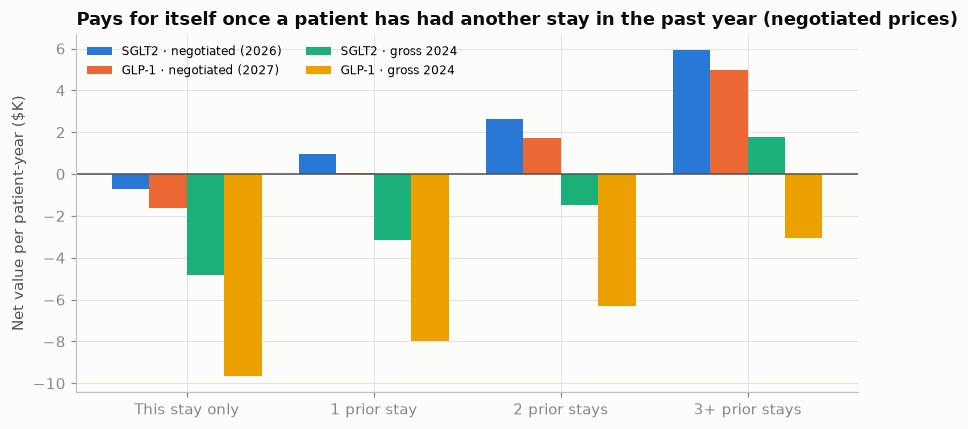

In [4]:
order = ["SGLT2 · negotiated (2026)", "GLP-1 · negotiated (2027)", "SGLT2 · gross 2024", "GLP-1 · gross 2024"]
x = np.arange(len(grp)); w = 0.2
fig, ax = plt.subplots(figsize=(8, 4))
for i, k in enumerate(order):
    ax.bar(x + (i - 1.5) * w, grp[k] / 1000, w, color=SERIES[i], label=k)
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks(x, grp.index); ax.set_ylabel("Net value per patient-year ($K)")
ax.set_title("Pays for itself once a patient has had another stay in the past year (negotiated prices)")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig(FIGURES / "06_net_value.png", dpi=160); plt.show()

## 3. The rule: "another hospital stay in the past year"

Turning the table into a decision rule a payer or hospital can apply at discharge, and sizing it **per 1,000 diabetic discharges**.

In [5]:
def rule_summary(annual_cost, factor=1.0, rrr=RRR["base"], cost=COST["base"]):
    q = p[p.number_inpatient >= 1]
    n = 1000 * len(q) / len(p)
    avoided = n * q.past12.mean() * factor * rrr
    net = n * net_value(q.past12.mean(), annual_cost, rrr, cost, factor)
    return {"qualifying per 1,000 discharges": n, "admissions avoided / yr": avoided,
            "drug cost / yr ($)": n * annual_cost, "hospital savings / yr ($)": avoided * cost, "net / yr ($)": net,
            "cost per admission avoided ($)": n * annual_cost / avoided}

rule = pd.DataFrame({k: rule_summary(v) for k, v in ANNUAL.items()}).T
rule.round(0)

,"qualifying per 1,000 discharges",admissions avoided / yr,drug cost / yr ($),hospital savings / yr ($),net / yr ($),cost per admission avoided ($)
SGLT2 · negotiated (2026),117.0,32.0,276808.0,490513.0,213704.0,8578.0
GLP-1 · negotiated (2027),117.0,32.0,385002.0,490513.0,105510.0,11930.0
SGLT2 · gross 2024,117.0,32.0,758881.0,490513.0,-268368.0,23516.0
GLP-1 · gross 2024,117.0,32.0,1324675.0,490513.0,-834163.0,41049.0


In [6]:
q = p[p.number_inpatient >= 1]
rest = p[p.number_inpatient == 0]
print(f"Qualifying patients: {len(q):,} of {len(p):,} ({len(q)/len(p):.1%})")
print(f"  30-day readmission: {q.readmit_30.mean():.1%} vs {rest.readmit_30.mean():.1%} for everyone else")
print(f"  heart or circulatory diagnosis: {q.has_heart_dx.mean():.1%}; kidney diagnosis: {q.has_kidney_dx.mean():.1%}")
print(f"  share of all 30-day readmissions that come from this group: {q.readmit_30.sum() / p.readmit_30.sum():.1%}")
print(f"  in the top 2 risk deciles from notebook 04: {(q.risk_decile >= 9).mean():.1%}")

Qualifying patients: 8,195 of 69,987 (11.7%)
  30-day readmission: 15.4% vs 8.1% for everyone else
  heart or circulatory diagnosis: 60.6%; kidney diagnosis: 15.3%
  share of all 30-day readmissions that come from this group: 20.1%
  in the top 2 risk deciles from notebook 04: 57.5%


## 4. How sure are we? Sensitivity analysis

Net value for the qualifying group at the **negotiated SGLT2 price**, moving one assumption at a time between its low and high value (tornado), then a grid of the two biggest drivers.

In [7]:
base_cost = ANNUAL["SGLT2 · negotiated (2026)"]
qm = q.past12.mean()
base = net_value(qm, base_cost)
tornado = pd.DataFrame([
    {"assumption": "Hospitalization reduction (4% – 18%)", "low": net_value(qm, base_cost, rrr=RRR["low"]), "high": net_value(qm, base_cost, rrr=RRR["high"])},
    {"assumption": "Cost per admission ($10,900 – $24,200)", "low": net_value(qm, base_cost, cost=COST["low"]), "high": net_value(qm, base_cost, cost=COST["high"])},
    {"assumption": "Future admissions (50% – 100% of past year)", "low": net_value(qm, base_cost, factor=0.5), "high": base},
    {"assumption": "Price (negotiated – gross 2024)", "low": net_value(qm, ANNUAL["SGLT2 · gross 2024"]), "high": base},
]).assign(swing=lambda d: (d.high - d.low).abs()).sort_values("swing", ascending=False)
print(f"Base case net value per qualifying patient-year: ${base:,.0f}")
tornado.round(0)

Base case net value per qualifying patient-year: $1,825


,assumption,low,high,swing
0,Hospitalization reduction (4% – 18%),-841.0,4491.0,5332.0
3,Price (negotiated – gross 2024),-2292.0,1825.0,4117.0
1,"Cost per admission ($10,900 – $24,200)",640.0,4305.0,3665.0
2,Future admissions (50% – 100% of past year),-269.0,1825.0,2095.0


In [8]:
rrr_grid = [0.04, 0.08, 0.11, 0.14, 0.18]
cost_grid = [10900, 15200, 20000, 24200]
grid = pd.DataFrame([[100 * (net_value(p.past12, base_cost, r, c) > 0).mean() for c in cost_grid] for r in rrr_grid],
                    index=[f"{r:.0%}" for r in rrr_grid], columns=[f"${c:,}" for c in cost_grid])
grid.index.name = "hospitalization reduction ↓ / admission cost →"
grid.round(1)

,"$10,900","$15,200","$20,000","$24,200"
hospitalization reduction ↓ / admission cost →,,,,
4%,0.3,1.3,3.4,3.4
8%,3.4,11.7,11.7,11.7
11%,11.7,11.7,11.7,100.0
14%,11.7,11.7,100.0,100.0
18%,11.7,100.0,100.0,100.0


**Reading the sensitivity.** The result is most sensitive to **how big the hospitalization effect really is** and to **price**. At the negotiated price and the trial's 11% effect, the qualifying group is positive, but it turns negative in three of the four single-assumption tests (low effect, half the future admissions, gross price). The grid shows the share of **all** diabetic inpatients for whom the drug pays for itself under each combination. The next cell checks the narrower group with **2+** prior stays.

In [9]:
def stress(q):
    m = q.past12.mean()
    return {"base": net_value(m, base_cost), "effect 4%": net_value(m, base_cost, rrr=RRR["low"]),
            "admission cost $10,900": net_value(m, base_cost, cost=COST["low"]), "future = 50% of past": net_value(m, base_cost, factor=0.5),
            "gross 2024 price": net_value(m, ANNUAL["SGLT2 · gross 2024"])}
STRESS = pd.DataFrame({"1+ prior stays": stress(p[p.number_inpatient >= 1]), "2+ prior stays": stress(p[p.number_inpatient >= 2])}).T.round(0)
STRESS

,base,effect 4%,"admission cost $10,900",future = 50% of past,gross 2024 price
1+ prior stays,1825.0,-841.0,640.0,-269.0,-2292.0
2+ prior stays,3869.0,-97.0,2106.0,753.0,-248.0


**Patients with 2+ prior stays** stay positive or within a few hundred dollars of break-even in **every** single-assumption test. That's the group to lead a pilot with. The broader 1+ group is positive in the base case but depends on the effect size, the price and how often they return.

In [10]:
half = pd.DataFrame({k: rule_summary(v, factor=0.5) for k, v in ANNUAL.items()}).T
two_plus = p[p.number_inpatient >= 2]
update_results("value", {
    "assumptions": A.reset_index().fillna("").to_dict("records"),
    "annual_cost": ANNUAL,
    "breakeven": breakeven.to_dict(),
    "groups": grp.reset_index().astype({"stays_group": str}).round(1).to_dict("records"),
    "rule": rule.reset_index().rename(columns={"index": "scenario"}).round(0).to_dict("records"),
    "rule_half": half.reset_index().rename(columns={"index": "scenario"}).round(0).to_dict("records"),
    "qualifying": {"n": int(len(q)), "pct": round(100 * len(q) / len(p), 1), "readmit_30": round(100 * q.readmit_30.mean(), 1),
                   "readmit_30_rest": round(100 * rest.readmit_30.mean(), 1), "heart_pct": round(100 * q.has_heart_dx.mean(), 1),
                   "kidney_pct": round(100 * q.has_kidney_dx.mean(), 1),
                   "share_of_readmissions": round(100 * q.readmit_30.sum() / p.readmit_30.sum(), 1),
                   "mean_admits": round(qm, 2), "two_plus_pct": round(100 * len(two_plus) / len(p), 1)},
    "base_net": round(base), "tornado": tornado.round(0).to_dict("records"),
    "stress": {k: {kk: float(vv) for kk, vv in v.items()} for k, v in STRESS.T.to_dict().items()},
    "grid": {"rrr": rrr_grid, "cost": cost_grid, "values": grid.round(1).values.tolist()},
})
print("saved")

saved
